In [99]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

import lightgbm as lgb

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

RANDOM_STATE = 42

In [100]:
DATA_DIR = Path("../data")
PROCESSED_DIR = DATA_DIR / "processed"

TRAIN_PATH = PROCESSED_DIR / "train_processed.csv"
VALIDATION_PATH = PROCESSED_DIR / "validation_processed.csv"

OUTPUT_DIR = Path("../outputs")

OUTPUT_DIR.mkdir(exist_ok=True)

In [101]:
print("Train exists:", TRAIN_PATH.exists())
print("Validation exists:", VALIDATION_PATH.exists())

Train exists: True
Validation exists: True


In [102]:
train = pd.read_csv(TRAIN_PATH)
validation = pd.read_csv(VALIDATION_PATH)

print("Training shape:", train.shape)
print("Validation shape:", validation.shape)

Training shape: (48000, 26)
Validation shape: (12000, 24)


In [103]:
train["date"] = pd.to_datetime(train["date"])
validation["date"] = pd.to_datetime(validation["date"])

In [104]:
print(train["date"].min())
print(train["date"].max())

print()

print(validation["date"].min())
print(validation["date"].max())

2025-01-01 00:00:00
2025-10-31 00:00:00

2025-11-01 00:00:00
2025-12-31 00:00:00


In [105]:
FEATURES = [
    # Freight
    "distance",
    "log_distance",
    "weight",
    "log_weight",
    "weight_missing",
    "equipment",

    # Geography
    "pickup",
    "delivery",
    "pickup_lat",
    "pickup_lon",
    "delivery_lat",
    "delivery_lon",
    "lane",
    "new_lane",

    # Market
    "market_index",
    "market_index_missing",
    "quote_signal",

    # Time
    "month",
    "week_of_year",
    "day_of_month",
    "day_of_week",
    "is_weekend"
]

TARGET = "log_posted_rate"

In [106]:
print("Number of features:", len(FEATURES))

Number of features: 22


In [107]:
CATEGORICAL_FEATURES = [
    "equipment",
    "pickup",
    "delivery",
    "lane"
]

In [108]:
for column in CATEGORICAL_FEATURES:
    train[column] = train[column].astype("category")

In [109]:
HOLDOUT_START = pd.Timestamp("2025-09-01")

train_data = train[
    train["date"] < HOLDOUT_START
].copy()

holdout_data = train[
    train["date"] >= HOLDOUT_START
].copy()

In [110]:
print("Training rows:", len(train_data))
print("Holdout rows:", len(holdout_data))

print()

print(
    "Training:",
    train_data["date"].min(),
    "to",
    train_data["date"].max()
)

print(
    "Holdout:",
    holdout_data["date"].min(),
    "to",
    holdout_data["date"].max()
)

Training rows: 38477
Holdout rows: 9523

Training: 2025-01-01 00:00:00 to 2025-08-31 00:00:00
Holdout: 2025-09-01 00:00:00 to 2025-10-31 00:00:00


In [111]:
X_train = train_data[FEATURES]
y_train = train_data[TARGET]

X_holdout = holdout_data[FEATURES]
y_holdout = holdout_data[TARGET]

actual_holdout_rate = holdout_data["posted_rate"]

In [112]:
print("X_train:", X_train.shape)
print("X_holdout:", X_holdout.shape)

X_train: (38477, 22)
X_holdout: (9523, 22)


In [113]:
baseline_rate = train_data["posted_rate"].median()

print("Baseline rate:", baseline_rate)

Baseline rate: 2026.04


In [114]:
baseline_predictions = np.full(
    len(holdout_data),
    baseline_rate
)

In [115]:
def evaluate_model(actual, predicted):
    
    mae = mean_absolute_error(actual, predicted)

    rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    mape = np.mean(
        np.abs((actual - predicted) / actual)
    ) * 100

    wape = (
        np.sum(np.abs(actual - predicted))
        / np.sum(actual)
    ) * 100

    print(f"MAE:  ${mae:,.2f}")
    print(f"RMSE: ${rmse:,.2f}")
    print(f"MAPE: {mape:.2f}%")
    print(f"WAPE: {wape:.2f}%")

In [116]:
print("BASELINE PERFORMANCE")
print("=" * 40)

evaluate_model(
    actual_holdout_rate,
    baseline_predictions
)

BASELINE PERFORMANCE
MAE:  $1,148.92
RMSE: $1,569.42
MAPE: 70.15%
WAPE: 48.02%


In [117]:
model = lgb.LGBMRegressor(
    objective="regression",

    n_estimators=3000,
    learning_rate=0.03,

    num_leaves=31,
    max_depth=-1,

    min_child_samples=40,

    subsample=0.8,
    subsample_freq=1,

    colsample_bytree=0.8,

    random_state=RANDOM_STATE,

    n_jobs=-1,
    verbosity=-1
)

In [118]:
model.fit(
    X_train,
    y_train,

    eval_set=[
        (X_holdout, y_holdout)
    ],

    eval_metric="l1",

    categorical_feature=CATEGORICAL_FEATURES,

    callbacks=[
        lgb.early_stopping(
            stopping_rounds=100,
            verbose=True
        )
    ]
)

Training until validation scores don't improve for 100 rounds
Early stopping, best iteration is:
[171]	valid_0's l1: 0.0495152	valid_0's l2: 0.0265391


LGBMRegressor(colsample_bytree=0.8, learning_rate=0.03, min_child_samples=40,
              n_estimators=3000, n_jobs=-1, objective='regression',
              random_state=42, subsample=0.8, subsample_freq=1, verbosity=-1)

In [119]:
print(
    "Best iteration:",
    model.best_iteration_
)

Best iteration: 171


In [120]:
holdout_log_predictions = model.predict(
    X_holdout
)

In [121]:
holdout_predictions = np.exp(
    holdout_log_predictions
)

In [122]:
print("LIGHTGBM PERFORMANCE")
print("=" * 40)

evaluate_model(
    actual_holdout_rate,
    holdout_predictions
)

LIGHTGBM PERFORMANCE
MAE:  $129.79
RMSE: $640.94
MAPE: 5.53%
WAPE: 5.42%


In [123]:
def get_metrics(actual, predicted):
    
    mae = mean_absolute_error(actual, predicted)

    rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    mape = np.mean(
        np.abs((actual - predicted) / actual)
    ) * 100

    wape = (
        np.sum(np.abs(actual - predicted))
        / np.sum(actual)
    ) * 100

    return {
        "MAE": mae,
        "RMSE": rmse,
        "MAPE": mape,
        "WAPE": wape
    }

In [124]:
results = pd.DataFrame({
    "Baseline": get_metrics(
        actual_holdout_rate,
        baseline_predictions
    ),

    "LightGBM": get_metrics(
        actual_holdout_rate,
        holdout_predictions
    )
}).T

results

,MAE,RMSE,MAPE,WAPE
Baseline,"1,148.92","1,569.42",70.15,48.02
LightGBM,129.79,640.94,5.53,5.42


In [125]:
holdout_results = holdout_data[
    [
        "load_id",
        "date",
        "pickup",
        "delivery",
        "lane",
        "equipment",
        "distance",
        "weight",
        "posted_rate"
    ]
].copy()

In [126]:
holdout_results["predicted_rate"] = (
    holdout_predictions
)

In [127]:
holdout_results["error"] = (
    holdout_results["posted_rate"]
    - holdout_results["predicted_rate"]
)

In [128]:
holdout_results["absolute_error"] = (
    holdout_results["error"].abs()
)

In [129]:
holdout_results.head(10)

,load_id,date,pickup,delivery,lane,equipment,distance,weight,posted_rate,predicted_rate,error,absolute_error
38477,TR-038478,2025-09-01,Savannah,Columbia,Savannah -> Columbia,Dry Van,126.80,"17,667.00",323.23,337.06,-13.83,13.83
38478,TR-038479,2025-09-01,El Paso,Phoenix,El Paso -> Phoenix,Flatbed,540.20,"34,846.00","1,264.20","1,312.64",-48.44,48.44
38479,TR-038480,2025-09-01,Nashville,Madison,Nashville -> Madison,Dry Van,549.30,"33,933.00","1,203.42","1,209.02",-5.60,5.60
38480,TR-038481,2025-09-01,Tampa,Charleston,Tampa -> Charleston,Dry Van,689.30,"39,417.00","1,478.30","1,444.71",33.59,33.59
38481,TR-038482,2025-09-01,Columbia,San Antonio,Columbia -> San Antonio,Dry Van,"1,103.70","35,657.00","2,311.83","2,213.12",98.71,98.71
38482,TR-038483,2025-09-01,St. Louis,Fresno,St. Louis -> Fresno,Dry Van,"1,955.50","28,673.00","3,527.11","3,666.96",-139.85,139.85
38483,TR-038484,2025-09-01,Montgomery,Greensboro,Montgomery -> Greensboro,Dry Van,437.40,"46,887.00","1,052.15","1,025.29",26.86,26.86
38484,TR-038485,2025-09-01,Cincinnati,Kansas City,Cincinnati -> Kansas City,Reefer,339.90,"38,681.00",907.09,948.52,-41.43,41.43
38485,TR-038486,2025-09-01,Philadelphia,Hartford,Philadelphia -> Hartford,Dry Van,71.40,"9,165.00",187.49,209.60,-22.11,22.11
38486,TR-038487,2025-09-01,Raleigh,Cincinnati,Raleigh -> Cincinnati,Dry Van,633.80,"29,410.00","1,347.42","1,322.98",24.44,24.44


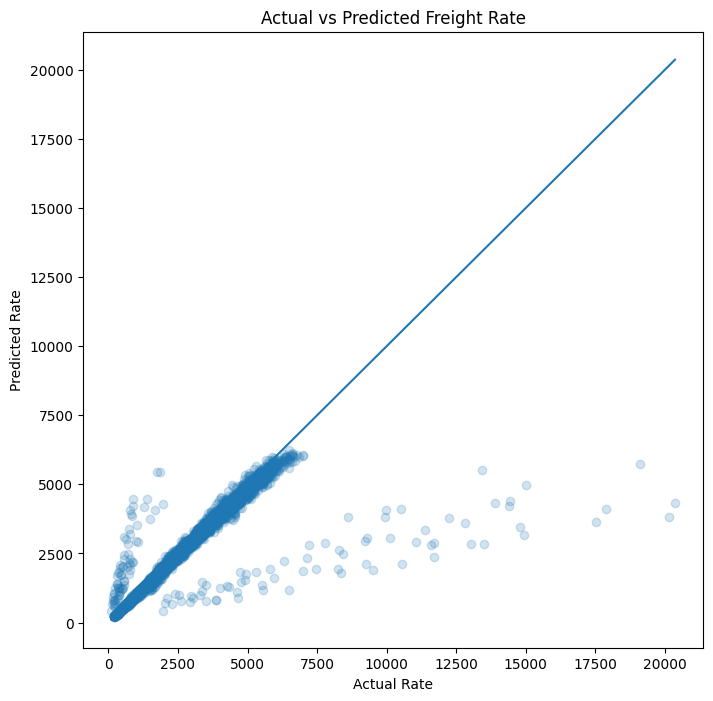

In [130]:
plt.figure(figsize=(8, 8))

plt.scatter(
    holdout_results["posted_rate"],
    holdout_results["predicted_rate"],
    alpha=0.2
)

minimum = min(
    holdout_results["posted_rate"].min(),
    holdout_results["predicted_rate"].min()
)

maximum = max(
    holdout_results["posted_rate"].max(),
    holdout_results["predicted_rate"].max()
)

plt.plot(
    [minimum, maximum],
    [minimum, maximum]
)

plt.xlabel("Actual Rate")
plt.ylabel("Predicted Rate")

plt.title(
    "Actual vs Predicted Freight Rate"
)

plt.show()

In [131]:
importance = pd.DataFrame({
    "feature": FEATURES,
    "importance": model.feature_importances_
})

In [132]:
importance = importance.sort_values(
    "importance",
    ascending=False
)

importance

,feature,importance
0,distance,1025
5,equipment,577
6,pickup,497
7,delivery,494
12,lane,477
2,weight,384
16,quote_signal,380
14,market_index,380
1,log_distance,274
18,week_of_year,205


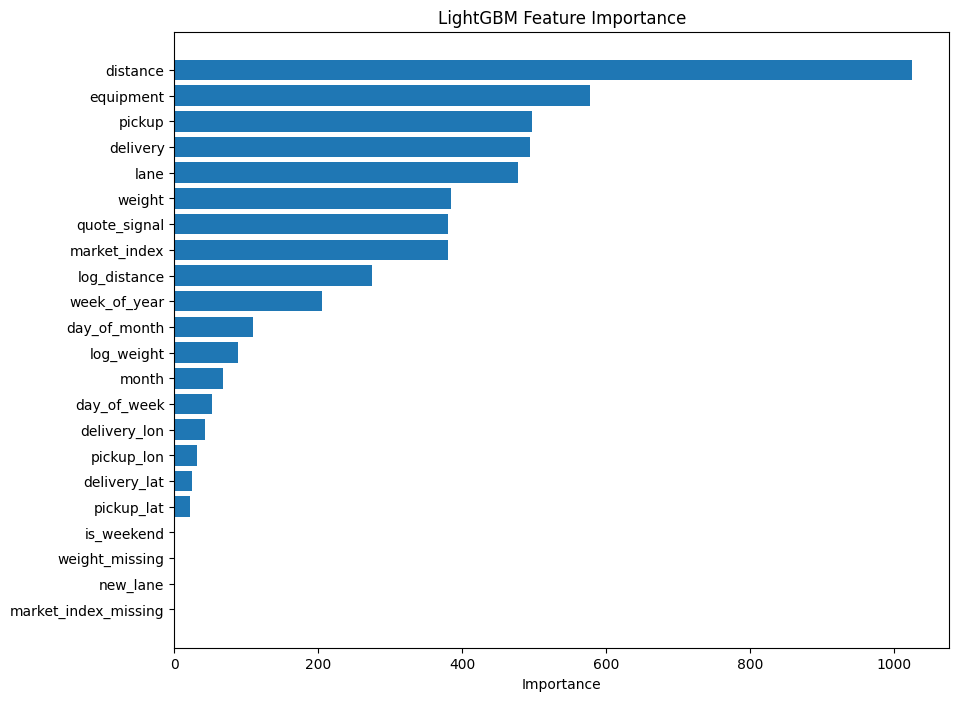

In [133]:
plt.figure(figsize=(10, 8))

plt.barh(
    importance["feature"],
    importance["importance"]
)

plt.gca().invert_yaxis()

plt.xlabel("Importance")
plt.title("LightGBM Feature Importance")

plt.show()

In [134]:
equipment_error = (
    holdout_results
    .groupby(
        "equipment",
        observed=True
    )["absolute_error"]
    .mean()
    .sort_values()
)

equipment_error

equipment
Dry Van   121.34
Flatbed   131.16
Reefer    147.68
Name: absolute_error, dtype: float64

In [135]:
holdout_results["percentage_error"] = (
    holdout_results["absolute_error"]
    / holdout_results["posted_rate"]
) * 100

In [136]:
holdout_results[
    "percentage_error"
].describe(
    percentiles=[
        0.50,
        0.75,
        0.90,
        0.95,
        0.99
    ]
)

count   9,523.00
mean        5.53
std        25.10
min         0.00
50%         2.49
75%         4.29
90%         6.66
95%         8.81
99%        75.22
max       477.47
Name: percentage_error, dtype: float64

In [137]:
best_trees = model.best_iteration_

print("Trees for final model:", best_trees)

Trees for final model: 171


In [138]:
X_final = train[FEATURES]
y_final = train[TARGET]

final_model = lgb.LGBMRegressor(
    objective="regression",
    n_estimators=best_trees,
    learning_rate=0.03,
    num_leaves=31,
    min_child_samples=40,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

final_model.fit(
    X_final,
    y_final,
    categorical_feature=CATEGORICAL_FEATURES
)

LGBMRegressor(colsample_bytree=0.8, learning_rate=0.03, min_child_samples=40,
              n_estimators=171, n_jobs=-1, objective='regression',
              random_state=42, subsample=0.8, subsample_freq=1, verbosity=-1)

In [139]:
X_validation = validation[FEATURES].copy()

for column in CATEGORICAL_FEATURES:
    X_validation[column] = pd.Categorical(
        X_validation[column],
        categories=X_final[column].cat.categories
    )

In [140]:
print(
    X_validation.isnull().sum()[
        X_validation.isnull().sum() > 0
    ]
)

pickup       725
delivery     722
lane        1461
dtype: int64


In [141]:
validation_log_predictions = final_model.predict(
    X_validation
)

validation_predictions = np.exp(
    validation_log_predictions
)

In [142]:
print("Predictions:", len(validation_predictions))
print("Minimum:", validation_predictions.min())
print("Maximum:", validation_predictions.max())
print("Average:", validation_predictions.mean())

Predictions: 12000
Minimum: 214.988736287806
Maximum: 6295.7657128337305
Average: 2338.9921024696573


In [143]:
submission = pd.DataFrame({
    "load_id": validation["load_id"],
    "predicted_rate": validation_predictions
})

submission.head()

,load_id,predicted_rate
0,TE-000001,850.93
1,TE-000002,"4,908.11"
2,TE-000003,"5,214.83"
3,TE-000004,"4,071.99"
4,TE-000005,"1,850.68"


In [144]:
print("Rows:", len(submission))
print("Missing:", submission.isnull().sum().sum())
print("Duplicate IDs:", submission["load_id"].duplicated().sum())
print("Non-positive rates:", (submission["predicted_rate"] <= 0).sum())

Rows: 12000
Missing: 0
Duplicate IDs: 0
Non-positive rates: 0


In [145]:
submission.to_csv(
    OUTPUT_DIR / "validation_predictions.csv",
    index=False
)

print("Saved successfully.")

Saved successfully.


In [146]:
check = pd.read_csv(
    OUTPUT_DIR / "validation_predictions.csv"
)

print(check.head())

print("\nRows:", len(check))
print("Columns:", check.columns.tolist())
print("Missing values:", check.isnull().sum().sum())
print("Duplicate IDs:", check["load_id"].duplicated().sum())
print("Non-positive rates:", (check["predicted_rate"] <= 0).sum())

     load_id  predicted_rate
0  TE-000001          850.93
1  TE-000002        4,908.11
2  TE-000003        5,214.83
3  TE-000004        4,071.99
4  TE-000005        1,850.68

Rows: 12000
Columns: ['load_id', 'predicted_rate']
Missing values: 0
Duplicate IDs: 0
Non-positive rates: 0


In [ ]:
december = pd.DataFrame({
    "date": pd.date_range("2025-12-01", "2025-12-31")
})

december["pickup"] = "Lexington"
december["delivery"] = "Fort Wayne"
december["distance"] = 360
december["equipment"] = "Dry Van"
december["weight"] = 32000

december["log_distance"] = np.log1p(december["distance"])
december["log_weight"] = np.log1p(december["weight"])
december["weight_missing"] = 0

december["month"] = december["date"].dt.month
december["week_of_year"] = december["date"].dt.isocalendar().week.astype(int)
december["day_of_month"] = december["date"].dt.day
december["day_of_week"] = december["date"].dt.dayofweek
december["is_weekend"] = (december["day_of_week"] >= 5).astype(int)

december["lane"] = "Lexington -> Fort Wayne"
december["new_lane"] = 0
december["market_index_missing"] = 0

pickup_row = train[train["pickup"].astype(str) == "Lexington"].iloc[0]
delivery_row = train[train["delivery"].astype(str) == "Fort Wayne"].iloc[0]

december["pickup_lat"] = pickup_row["pickup_lat"]
december["pickup_lon"] = pickup_row["pickup_lon"]
december["delivery_lat"] = delivery_row["delivery_lat"]
december["delivery_lon"] = delivery_row["delivery_lon"]

market = (
    validation[validation["date"].dt.month == 12]
    .groupby("date")[["market_index", "quote_signal"]]
    .mean()
    .reset_index()
)

december = december.merge(market, on="date", how="left")

for col in CATEGORICAL_FEATURES:
    december[col] = pd.Categorical(
        december[col],
        categories=X_final[col].cat.categories
    )

december["predicted_rate"] = np.exp(
    final_model.predict(december[FEATURES])
).round(2)

december_output = december[
    ["pickup", "delivery", "distance",
     "equipment", "weight", "date", "predicted_rate"]
].copy()

december_output["date"] = december_output["date"].dt.strftime("%Y-%m-%d")

december_output.to_csv(
    OUTPUT_DIR / "december_chart_predictions.csv",
    index=False
)

display(december_output)

,pickup,delivery,distance,equipment,weight,date,predicted_rate
0,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-01,837.01
1,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-02,837.01
2,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-03,839.14
3,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-04,840.08
4,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-05,837.78
5,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-06,837.01
6,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-07,837.01
7,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-08,837.12
8,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-09,837.12
9,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-10,839.24


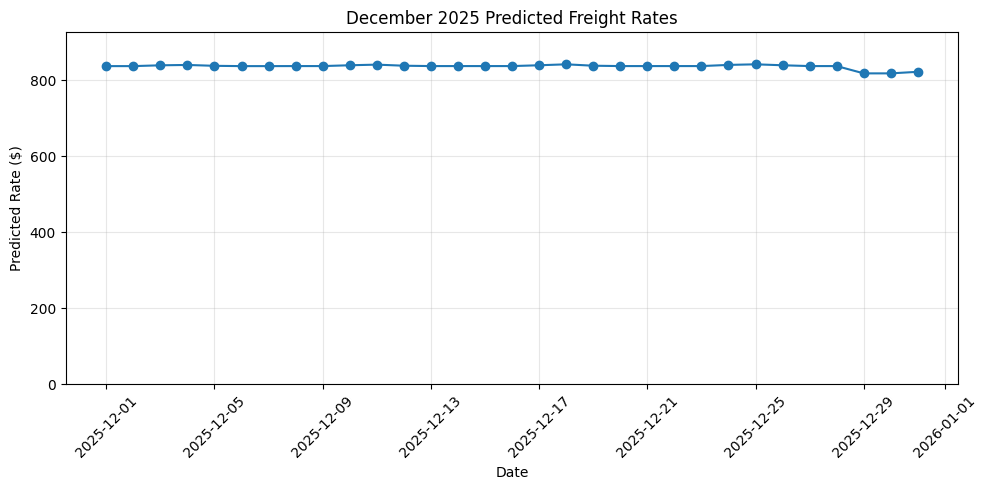

In [148]:
plt.figure(figsize=(10, 5))

plt.plot(
    pd.to_datetime(december_output["date"]),
    december_output["predicted_rate"],
    marker="o"
)

plt.title("December 2025 Predicted Freight Rates")
plt.xlabel("Date")
plt.ylabel("Predicted Rate ($)")

plt.xticks(rotation=45)

plt.ylim(0, december_output["predicted_rate"].max() * 1.1)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()